# Classifying 5M bank documents on a Rs 1,00,000 budget: a walkthrough

This notebook runs the whole pipeline's training and evaluation from the repo, and shows every number in the approach note: how one document moves through the steps, accuracy per class, the sealed test sets, the LLM comparison, the budget controller and the cost model. It was run end to end before submission, so the outputs below are real.

**To run it yourself:** open it in Colab (the button in the README) and choose Runtime, Run all; the first cell clones the repo and installs everything (about 5 minutes), and the rest takes about 20-30 minutes on Colab's free CPU. Or run it locally from the repo (about 15 minutes on a laptop).

**What is replayed, and why.** Three slow or paid things come from `artifacts/` instead of being recomputed:
- the OCR text of the 4,027-file dev sample (about an hour of CPU),
- the page features from the document-vision model (DiT),
- **the LLM answers.** These were made with `claude -p` on a Claude subscription and are replayed from a cache here. **To classify your own documents with the LLM step you need your own Claude subscription (the `claude` CLI) or an API key**; without one, `scripts/classify.py --no-llm` still runs everything else and marks those documents `NEEDS_LLM`.

The sealed test sets (lockboxes) are not re-run: each was run exactly once, by design, and only its saved results are shown.

**How the pipeline works** is in `README.md` and `pipeline/README.md`; every decision and its reasoning is in `DECISIONS.md`.

In [1]:
import os, sys, json, subprocess
from IPython.display import Image, display

PY = sys.executable

def step(module, *args):
    """Run one of the repo's scripts, showing its output as it comes (some steps take minutes); stop here if it fails."""
    proc = subprocess.Popen([PY, "-m", module, *args], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
                            env=dict(os.environ, PYTHONUNBUFFERED="1"))
    for line in proc.stdout:
        if "Warning" not in line and "warn(" not in line and "Loading weights" not in line:
            print(line, end="", flush=True)
    if proc.wait():
        raise RuntimeError(f"{module} failed (exit code {proc.returncode}); its output is above")

def pip_install(*args):
    out = subprocess.run([PY, "-m", "pip", "install", "-q", *args], capture_output=True, text=True)
    if out.returncode:
        print(out.stdout[-4000:], out.stderr[-4000:], sep="\n")
        raise RuntimeError("pip install failed; its output is above")

if "google.colab" in sys.modules:       # on Colab: fetch the repo and install the pinned packages (Colab's own torch is kept)
    if not os.path.exists("/content/privy-doc-classifier"):
        subprocess.run(["git", "clone", "-q", "https://github.com/vansh-gandhi-02/privy-doc-classifier", "/content/privy-doc-classifier"], check=True)
    else:                               # a clone left by an earlier run: bring it up to date
        subprocess.run(["git", "-C", "/content/privy-doc-classifier", "pull", "-q"], check=True)
    os.chdir("/content/privy-doc-classifier")
    keep_colab = ("#", "torch", "nbclient", "ipykernel", "nbformat")   # Colab's own torch and notebook machinery stay as they are
    reqs = [l for l in open("requirements.txt") if l.strip() and not l.startswith(keep_colab)]
    open("/tmp/requirements-colab.txt", "w").writelines(reqs)
    pip_install("-r", "/tmp/requirements-colab.txt")
    # the OCR package declares Python < 3.13 but runs on 3.13 (Colab's Python); its dependencies come from requirements.txt
    pip_install("--no-deps", "--ignore-requires-python", "rapidocr-onnxruntime==1.4.4")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")                      # locally: run everything from the repo root

step("tools.artifacts", "unpack")

unpacked 19 files


## 1. L1: the page layout

A frozen document-vision model (DiT) describes each page; a small logistic regression on top, trained in seconds, gives P(class | page). PoI and PoA are one class here ("kyc_id"); the address question splits them later.

In [2]:
step("scripts.train_l1")

  C=0.003  calib NLL 0.350
  C=0.01   calib NLL 0.281
  C=0.03   calib NLL 0.253
  C=0.1    calib NLL 0.244
  C=0.3    calib NLL 0.252

chosen C=0.1, temperature 1.06
layout alone, dev-test first pages (n=740): accuracy 0.885, top-2 0.999, bucket accuracy 0.999, macro-F1 0.877, calibration error 0.019

with the format prior, threshold 0.95:
  type settled by L1: 63.6% (accuracy 1.000; KYC ones go to the address question)
  bucket locked:  27.8% (bucket right 1.000)
  escalated:      8.5%
  cross-bucket confusion of the top class (D4 test, regroup if > 1-2%): 0.7%

per class (accept / lock / escalate):
  bank_statement           95%    0%    5%   n=78
  cc_statement             91%    2%    7%   n=44
  kyc_id                   94%    0%    6%   n=135
  loan_application          0%  100%    0%   n=57
  cc_application            0%   92%    8%   n=36
  salary_slip              93%    2%    5%   n=60
  itr                      91%    0%    9%   n=54
  gst                      92%    0%    

## 2. The bundle splitter

Where a merged PDF starts a new document. Printed page numbers overrule it (D30); see section 6.

In [3]:
step("scripts.train_bundles")

trained on 3418 page pairs (2275 boundaries)
threshold 0.40 (calibration boundary F1 0.993)

dev-test boundaries: precision 0.989, recall 0.989
bundles split exactly right: 29/30
single multi-page documents wrongly split: 1/191
correctly split segments whose top class from layout + prior is right: 107/117
pair-model weights [cos, js, argmax change, first-page score, shape, area, kind change, scanner change]: [-0.12999999523162842, 2.009999990463257, 1.4800000190734863, 8.239999771118164, 0.5400000214576721, 1.2799999713897705, 1.5700000524520874, 0.07000000029802322]


## 3. L2: the text model and the address question

Letter pieces plus checksummed Indian IDs, one model over all 15 classes, calibrated per reading depth. Then L0 to L2 runs on the calibration and dev-test documents. The discriminator table shows the words that separate each confusable pair.

In [4]:
step("scripts.train_l2")

training rows: 4304 (from 2720 documents), calibration rows: 1447, features: 80020
  C=3    calib NLL 0.141
  C=10   calib NLL 0.096
  C=30   calib NLL 0.081
  C=100  calib NLL 0.080
  C=300  calib NLL 0.116
chosen C=100; temperature per view: native 0.08, sel 0.92, full1 0.93, more 0.05

text alone on dev-test (accuracy over the 15 model classes, documents that have that view):
  native  n= 351  accuracy 1.000  confident >= 95%: 100.0%
  sel     n= 486  accuracy 0.918  confident >= 95%: 80.7%
  full1   n= 486  accuracy 0.984  confident >= 95%: 95.1%
  more    n= 152  accuracy 0.993  confident >= 95%: 100.0%

discriminator table (weight gap w_A - w_B; letter pieces are of the normalised text):
      loan_application: oana, loana, loa, loan, nappl, napp, oanap, anapp
        cc_application: ardap, rdap, carda, dappl, rdapp, dapp, dap, arda
     class10_marksheet: econa, cona, secon, seco, darys, rysc, arysc, rysch
     class12_marksheet: seni, senio, enio, enior, nior, sen, niors, ior
 

## 4. L3: how much should the LLM think?

Three ways of asking, on 150 hard documents, replayed from the cached answers. The rule, set in advance: the cheapest mode whose accuracy is at least 95% with 90% confidence.

In [5]:
step("scripts.run_l3_compare")

documents settled below 99%: 220 (96 as a critical class)
hard set: 150 (13 sent to L3 by L2, the rest settled below 99%); calib 66, dev-test 84
540 calls cached, 0 to make

mode     acc hard  acc calib  offered  in tok  out tok  think  Rs/call   sec  L3 docs on dev-test settled (right)
label       0.913      0.939    95.3%     619        6      3   0.0141   4.0  4/4 (4)
quote       0.987      1.000    95.3%     644      270    181   0.0379   5.1  3/4 (3)
think       0.987      1.000    95.3%     619      289    286   0.0391   5.1  3/4 (3)
label+think: thinking needed on 0% of L3 documents; Rs 0.0141 per L3 document; settles 4/4
quote+think: thinking needed on 25% of L3 documents; Rs 0.0477 per L3 document; settles 3/4

end to end on dev-test (n=843); at 5M about 17,923 documents reach L3:
  label        macro-F1 0.999 (L4 as error) / 0.999 (L4 left out); to L4 0.0%; at 5M: LLM Rs 254 + humans Rs 0 = Rs 254
               critical recall (L4 as miss): proof 1.000, proof 1.000, legal 1.

## 5. How one document moves through the pipeline

Five dev-test documents, run through the same code the pipeline uses, with their class probabilities after every step: the format prior (L0), the layout (L1), each reading rung (L2), the address question, the LLM (L3). Green is the true class; the red line is the 95% gate where a document is accepted.

1. A scanned passbook (the interviewer's example): it shares its words with a bank statement, but the layout alone settles it.
2. A Class 12 marksheet: layout cannot tell Class 10 from 12 (50/50); a selective read of a few lines decides it.
3. An Aadhaar card: layout says "KYC ID document"; the address question splits it into Proof of Address.
4. A Class 10 marksheet that layout gets wrong (82% Class 12): reading pulls it back, and the LLM settles it.
5. A card application whose first page shows neither a card type nor a loan amount: the LLM says "none of these", so it goes to a person.


A scanned passbook (true class: Other)  [78/78e0e5cb0aa4efc83e52.tif]  true class: Other (passbook etc.)
  L0: prior for a TIFF               Loan application 20.1%, Property 19.2%, KYC ID document 16.0%
  L1: layout                         Other (passbook etc.) 99.7%, KYC ID document 0.1%, Legal contract 0.1%
  -> accepted: Other (passbook etc.)

A scanned Class 12 marksheet  [0d/0dd8f2a70162d9d2c733.png]  true class: Class 12 marksheet
  L0: prior for a PNG                KYC ID document 49.7%, Salary slip 9.9%, Other (passbook etc.) 8.1%
  L1: layout                         Class 10 marksheet 50.5%, Class 12 marksheet 49.2%, ITR 0.1%
  L2: selective read                 Class 12 marksheet 100.0%, Class 10 marksheet 0.0%, ITR 0.0%
  -> accepted: Class 12 marksheet

An Aadhaar card with an address (true class: Proof of Address)  [0c/0cd72861d0133b234fbd.pdf]  true class: Proof of Address
  L0: prior for a PDF                Bank statement 18.4%, ITR 11.7%, KYC ID document 11.6%
  L1:

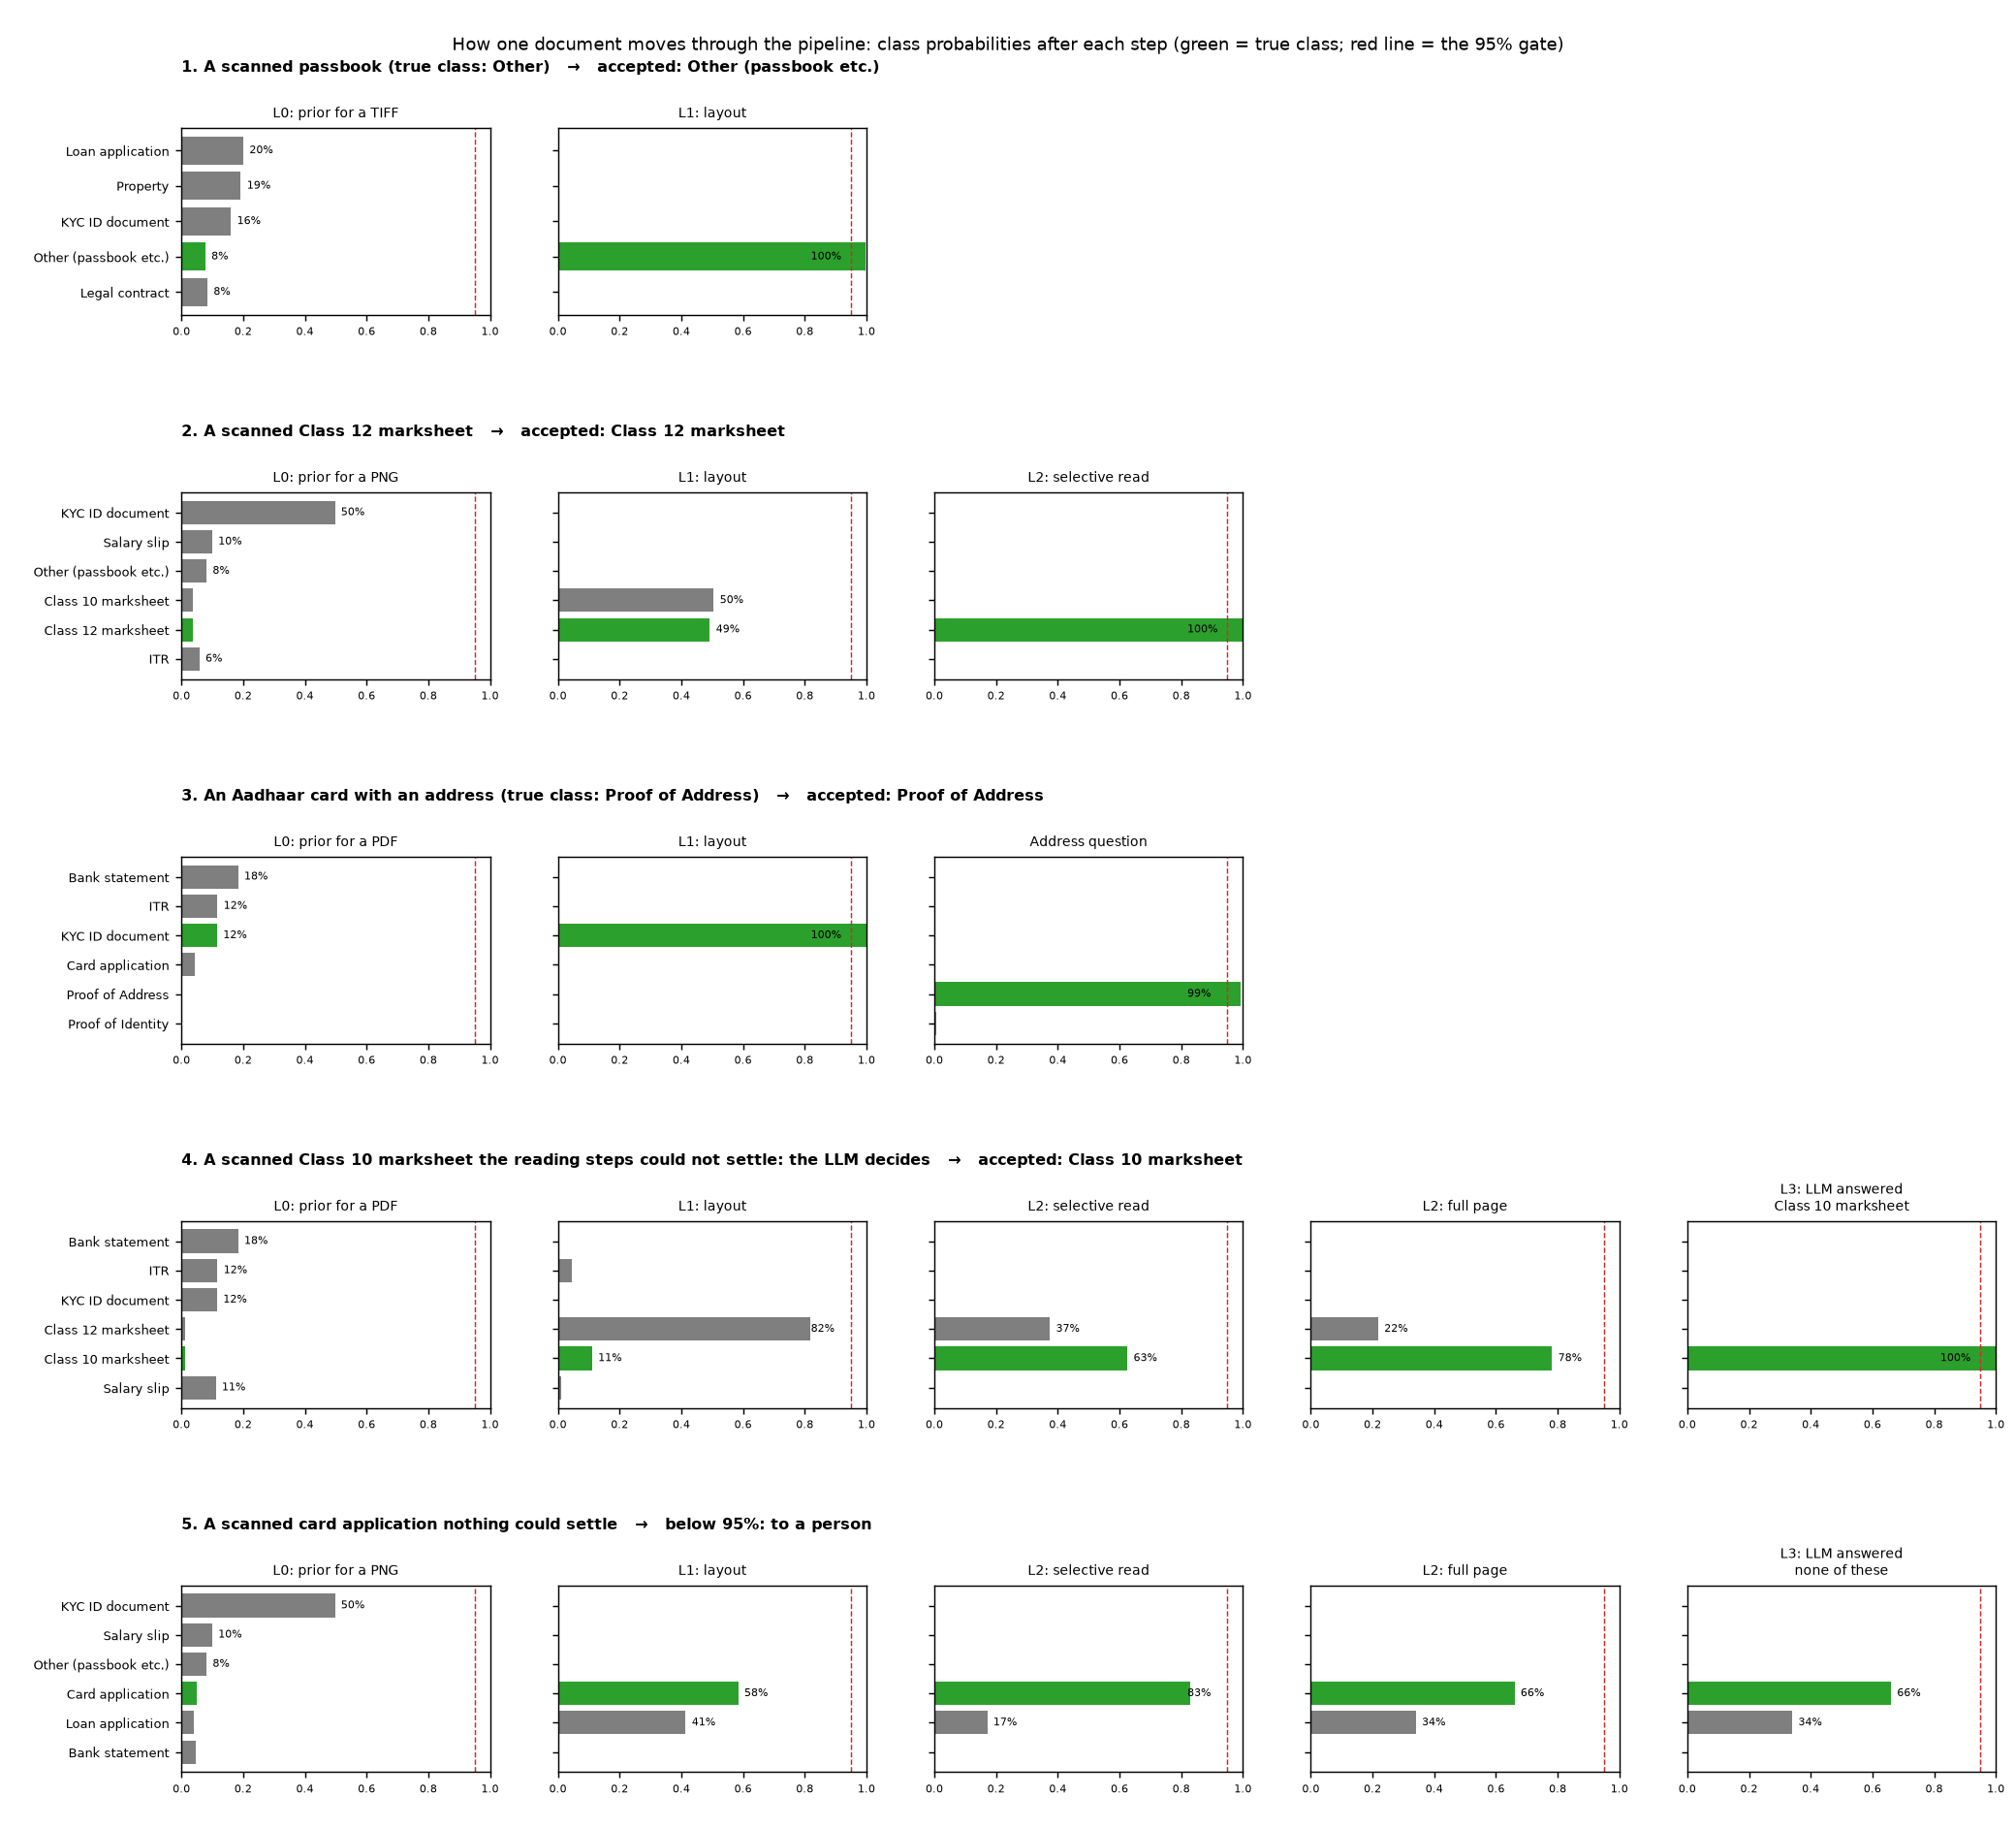

In [6]:
step("scripts.trace_document")
display(Image("data/sample/how_a_document_moves.png"))

## 6. The brief's bar: precision, recall and F1 per class

Macro-F1 must be at least 0.85 over the 15 classes and recall at least 0.90 on the critical classes (marked *). Documents sent to a person count as errors.

In [7]:
step("scripts.report_bar")


Dev-test, after L3 (human review counted as errors)  (n=843)
  macro-F1 0.998 (bar 0.85) | lowest critical recall 1.000 (bar 0.90) | PASSES
  class                                    precision  recall     F1     n
  Bank Statement                               1.000   1.000  1.000    96
  Credit Card Statement                        1.000   1.000  1.000    44
  Proof of Identity *                          1.000   1.000  1.000    90
  Proof of Address *                           1.000   1.000  1.000    45
  Loan Application Form                        1.000   0.984  0.992    64
  Credit Card Application                      0.974   0.974  0.974    39
  Salary Slip                                  1.000   1.000  1.000    70
  ITR                                          1.000   1.000  1.000    54
  GST Registration / Return                    1.000   1.000  1.000    45
  Audited Financial Statements                 1.000   1.000  1.000    33
  Company Constitution & Board Resolution    

## 7. Merged PDFs from an unfamiliar source

On bank statements from another generator (AgamiAI), the layout-only splitter cut each statement into pieces. Reading the printed page numbers fixed it on a dev batch of 80 statements without hurting our own bundles; the sealed Lockbox D (120 more statements) is the single final check (section 6 above).

In [8]:
print(json.dumps(json.load(open("data/sample/splitter_eval.json")), indent=1))

{
 "dev_test (ours)": {
  "layout only": {
   "bundles_exact": "29/30",
   "singles_split": "1/191"
  },
  "with page numbers": {
   "bundles_exact": "29/30",
   "singles_split": "1/191"
  }
 },
 "agami_dev (80 fresh statements)": {
  "layout only": {
   "pieces_per_file": 2.5,
   "kept_whole": "16/80"
  },
  "with page numbers": {
   "pieces_per_file": 1.0,
   "kept_whole": "80/80"
  },
  "page-number reads, CPU s per scanned page": 1.351
 }
}


## 8. The budget controller

A simulated 5M-document run with a scan-heavy stretch in the middle. The controller compares spend with a straight plan line after every batch and moves one gate (tau, 85-99%) at every step before the LLM. Then the same run with the budget squeezed to Rs 23k.

re-running the path for 1669 documents at 8 gate settings...

L3 mode quote (Rs 0.0379/call); target Rs 45,000 (after the 10% reserve)
  tau   Rs at 5M   to L3   to L4  accuracy (L4 as error)
 0.85     20,678    0.2%    0.1%                   0.979
 0.87     20,720    0.2%    0.1%                   0.986
 0.89     20,914    0.2%    0.1%                   0.989
 0.91     21,080    0.2%    0.1%                   0.992
 0.93     21,259    0.4%    0.1%                   0.995
 0.95     21,601    0.5%    0.1%                   0.998
 0.97     22,107    1.4%    0.2%                   0.996
 0.99     24,337    2.7%    0.2%                   0.996
raising tau above 95% does not buy accuracy on dev-test, so the controller will not raise it
spend by item (controlled run): fixed Rs 13,599, reads Rs 9,257, llm Rs 1,336, human Rs 0

without the controller (tau fixed at 0.95): spent Rs 24,192
with the controller: spent Rs 24,192 against Rs 45,000; tau ended at 0.950 (lowest 0.950, highest 0.950)
doc

re-running the path for 1669 documents at 8 gate settings...

L3 mode quote (Rs 0.0379/call); target Rs 23,000 (after the 10% reserve)
  tau   Rs at 5M   to L3   to L4  accuracy (L4 as error)
 0.85     20,678    0.2%    0.1%                   0.979
 0.87     20,720    0.2%    0.1%                   0.986
 0.89     20,914    0.2%    0.1%                   0.989
 0.91     21,080    0.2%    0.1%                   0.992
 0.93     21,259    0.4%    0.1%                   0.995
 0.95     21,601    0.5%    0.1%                   0.998
 0.97     22,107    1.4%    0.2%                   0.996
 0.99     24,337    2.7%    0.2%                   0.996
raising tau above 95% does not buy accuracy on dev-test, so the controller will not raise it
spend by item (controlled run): fixed Rs 13,599, reads Rs 9,127, llm Rs 1,027, human Rs 0

without the controller (tau fixed at 0.95): spent Rs 24,192
with the controller: spent Rs 23,753 against Rs 23,000; tau ended at 0.861 (lowest 0.861, highest 0.950)
doc

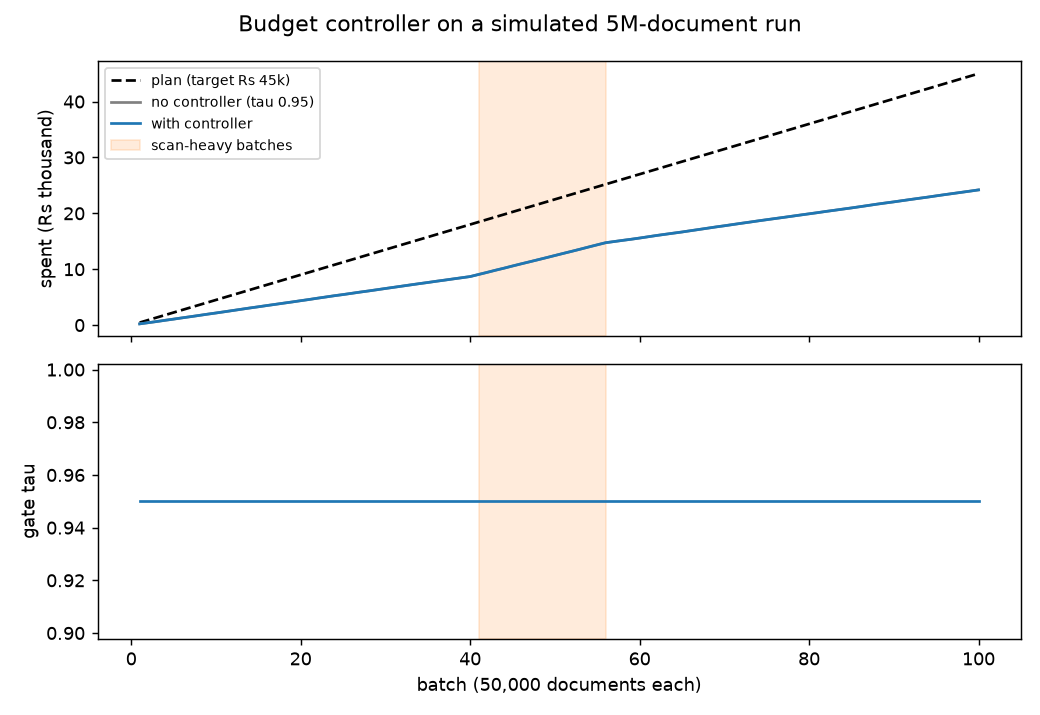

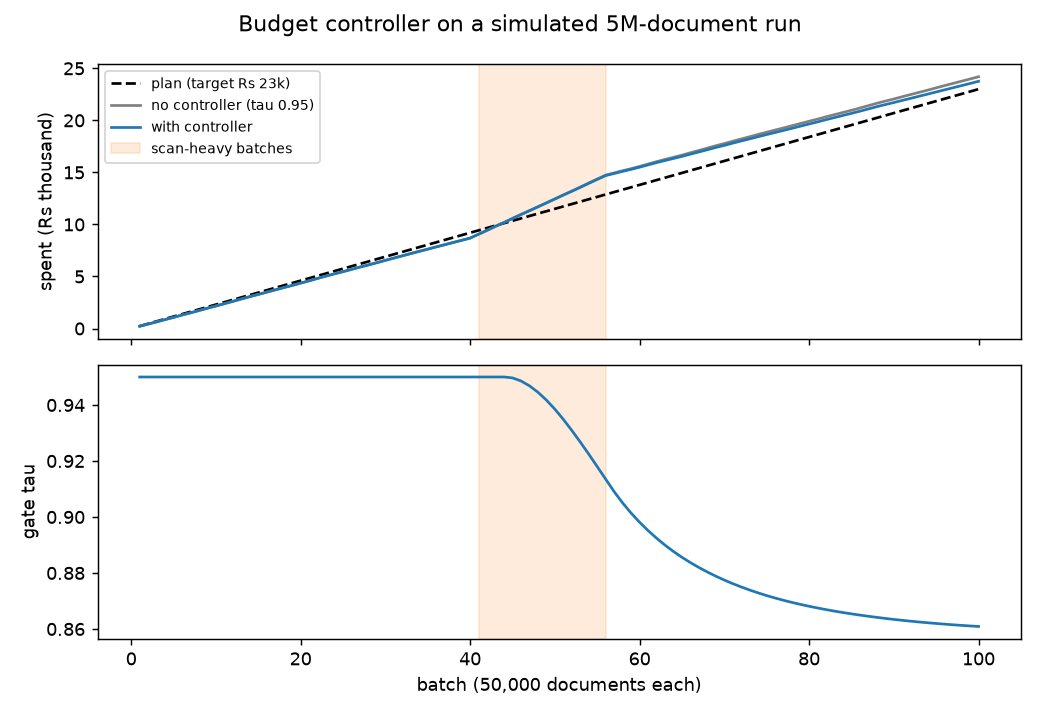

In [9]:
step("scripts.run_controller_demo")
step("scripts.run_controller_demo", "23000")
display(Image("data/sample/controller.png"), Image("data/sample/controller_23000.png"))

## 9. What 5M documents cost, and how sure we are

Unit costs measured on one CPU core (`costs/timing.py`), the 5M estimate with a 95% interval, and how far each assumption we could not measure moves it. Then the brute-force comparison.

In [10]:
step("costs.timing")
step("costs.precision")
step("costs.baseline")

CPU seconds on one core (mean of the samples):
  l0_s_per_file          0.003
  l1_s_per_page          0.113
  dit_s_per_page         0.076
  ocr_selective_s        0.482
  ocr_full_s             2.248
  ocr_page_cue_s         0.467
fixed per-page costs at 5M on this Mac: Rs 6,076 (9.2M pages, 5.3M scanned, 4.0M in multi-page scanned files)


Unit costs (CPU seconds on one core of this Mac; 95% interval of the mean):
  selective read         0.482 s +/- 3.1%  (n=150)
  full read              2.248 s +/- 7.8%  (n=150)
  page-number read       0.467 s +/- 2.1%  (n=60)
  L1 render + signals    0.037 s +/- 3.1%  (n=200)
  L1 DiT on CPU          0.076 s +/- 1.3%  (n=10)
  LLM call (quote)       Rs 0.0379 +/- 5.4%  (n=180, from token counts)

Per-document rates (class-mix weighted, 1669 documents): full reads 0.331, LLM 0.0062, human 0.0005

5M estimate at the default gate (cloud vCPU 2x, 3 pages per PDF, human review at Rs 0):
  L0           Rs        33
  L1           Rs     2,310
  selective    Rs     5,661
  page numbers Rs     4,149
  full reads   Rs     8,280
  LLM          Rs     1,169
  human        Rs         0
  total        Rs    21,601
  95% interval from measurement: Rs 20,449 to Rs 22,766 (-5.3% / +5.4%)

Assumptions (one at a time, everything else as above):
  cloud vCPU as fast as this Mac (1x)              Rs    

## 10. How much personal data the LLM masker removes

Measured on the Maskara Indian PII test set (Hugging Face, MIT); downloads about 20 MB the first time.

In [11]:
step("scripts.check_masker")


template_disjoint_eval (15000 texts): share of PII spans removed by the masker
  PERSON_NAME        0.0%  (n=8785)
  PHONE             83.7%  (n=7079)
  AADHAAR           87.0%  (n=4079)
  EMAIL             99.0%  (n=3004)
  DATE_OF_BIRTH     68.1%  (n=2490)
  ADDRESS           56.3%  (n=2420)
  DRIVER_LICENSE   100.0%  (n=1413)
  VEHICLE_REG       97.3%  (n=1385)
  API_KEY            7.5%  (n=1066)
  IP_ADDRESS         0.0%  (n=1058)
  USERNAME           0.0%  (n=1044)
  UPI_ID           100.0%  (n=983)
  PASSWORD           0.7%  (n=968)
  PASSPORT         100.0%  (n=891)
  PAN_CARD         100.0%  (n=813)
  CREDIT_CARD      100.0%  (n=698)
  SSN               34.3%  (n=373)

real_world_eval (2600 texts): share of PII spans removed by the masker
  PERSON_NAME        0.0%  (n=2200)
  PHONE             84.8%  (n=1200)
  AADHAAR           87.5%  (n=1000)
  EMAIL            100.0%  (n=700)
  UPI_ID           100.0%  (n=500)
  PAN_CARD         100.0%  (n=400)
  ADDRESS           59.0%  (n

## 11. Live, end to end, on freshly generated documents

Generates 20 new documents and runs L0, L1, the reading ladder, L2 and the address question on them (the first run downloads DiT, about 350 MB). Documents that would need the LLM use it only if the `claude` CLI is installed. To run the pipeline on your own folder: `python -m scripts.classify <folder> [--no-llm]`.

In [12]:
step("scripts.live_demo", "20")

generated 20 documents in 2s
  demo_000.pdf     PDF   true property_collateral    pred property_collateral    stopped at native text
  demo_001.jpg     JPG   true proof_of_address       pred proof_of_address       stopped at address question
  demo_002.pdf     PDF   true legal_contract         pred legal_contract         stopped at full page
  demo_003.pdf     PDF   true bank_statement         pred bank_statement         stopped at native text
  demo_004.txt     TXT   true bank_statement         pred bank_statement         stopped at native text
  demo_005.pdf     PDF   true bank_statement         pred bank_statement         stopped at native text
  demo_006.tif     TIFF  true property_collateral    pred property_collateral    stopped at more pages
  demo_007.docx    DOCX  true loan_application       pred loan_application       stopped at native text
  demo_008.pdf     PDF   true salary_slip            pred salary_slip            stopped at native text
  demo_009.docx    DOCX  true leg